# Exploratory Data Analysis

Analysis of the raw training dataset before preprocessing, focusing on feature distributions, missing values, class imbalance, and relationships between variables. The goal is to identify potential data quality issues and guide feature selection and preprocessing decisions.

The target variable `_MICHD` is based on self-reported health information rather than a prospective clinical diagnosis.

## 1. Load raw data

First, the raw training and test datasets are loaded. Their shapes are checked to see how many rows and features each dataset contains. The feature names and target labels are also inspected to get a better understanding of the data before starting the analysis. Additionally, the first few rows and columns are displayed to get an initial look at how the data is structured.

In [86]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from src.helpers import load_csv_data, load_feature_names

raw_data_path = "data/raw_dataset/"
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(raw_data_path)
feature_names = np.array(load_feature_names(raw_data_path))

print("Train:", x_train.shape, "Test:", x_test.shape)
print("Labels:", np.unique(y_train, return_counts=True))
print("Features:", len(feature_names))
assert x_train.shape[1] == len(feature_names)
assert len(x_train) == len(y_train) == len(train_ids)

Train: (328135, 321) Test: (109379, 321)
Labels: (array([-1,  1]), array([299160,  28975]))
Features: 321


In [87]:
print(" | ".join(feature_names[:10]))
for row in x_train[:5, :10]:
    print(" | ".join(f"{value:.1f}" for value in row))

_STATE | FMONTH | IDATE | IMONTH | IDAY | IYEAR | DISPCODE | SEQNO | _PSU | CTELENUM
53.0 | 11.0 | 11162015.0 | 11.0 | 16.0 | 2015.0 | 1100.0 | 2015015629.0 | 2015015629.0 | nan
33.0 | 12.0 | 12152015.0 | 12.0 | 15.0 | 2015.0 | 1200.0 | 2015004387.0 | 2015004387.0 | 1.0
20.0 | 10.0 | 10202015.0 | 10.0 | 20.0 | 2015.0 | 1100.0 | 2015005638.0 | 2015005638.0 | 1.0
42.0 | 6.0 | 6182015.0 | 6.0 | 18.0 | 2015.0 | 1100.0 | 2015004694.0 | 2015004694.0 | nan
24.0 | 11.0 | 11062015.0 | 11.0 | 6.0 | 2015.0 | 1100.0 | 2015004673.0 | 2015004673.0 | 1.0


## 2. Target balance
Next, the distribution of the target variable `_MICHD` is examined to see how many positive and negative cases there are in the dataset. The target labels are encoded as $-1$ and $1$, representing negative and positive cases.

Label -1: 299,160 (91.17%)
Label 1: 28,975 (8.83%)


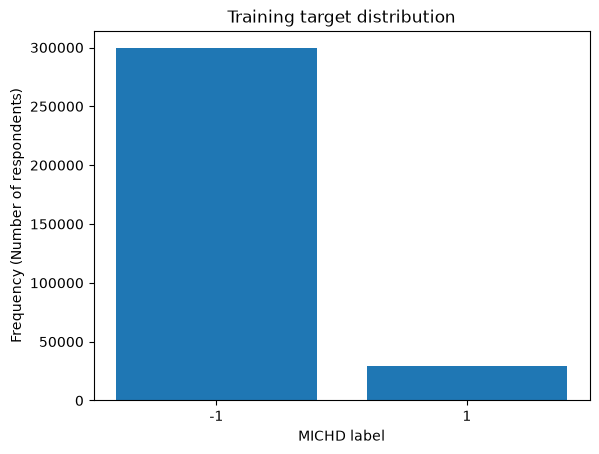

In [88]:
classes, counts = np.unique(y_train, return_counts=True)
for c, count in zip(classes, counts):
    print(f"Label {c}: {count:,} ({count / len(y_train):.2%})")

plt.bar([str(c) for c in classes], counts)
plt.xlabel("MICHD label")
plt.ylabel("Frequency (Number of respondents)")
plt.title("Training target distribution")
plt.show()

The distribution shows a significant class imbalance, with negative cases making up around $91%$ of the dataset and positive cases only around $9%$. This imbalance could affect model training and evaluation, since a model might favor the majority class. Therefore, accuracy alone might not be a reliable measure of model performance, and other evaluation metrics should also be considered.

## 3. Administrative and survey-related features
Administrative and survey-related features are identified using the BRFSS 2015 codebook. These include interview dates, identifiers, survey design variables, and sampling weights. These features do not directly describe the respondents' health or lifestyle and may not be useful for predicting `_MICHD`. Therefore, they are identified and added to the `features_to_drop` list for removal during preprocessing.

In [89]:
features_to_drop = [
    "IDATE", "IMONTH", "IDAY", "IYEAR", "FMONTH",
    "SEQNO", "_PSU", "DISPCODE", "_STSTR",
    "_STRWT", "_RAWRAKE", "_WT2RAKE", "_LLCPWT"
]

#Possible additional survey-related features
keywords = [
    "DATE", "MONTH", "YEAR", "SEQ",
    "STRAT", "RAKE", "PSU",
    "PHONE", "SAMP", "DISP"
]

additional_candidates = [
    name for name in feature_names
    if any(word in name.upper() for word in keywords)
    and name not in features_to_drop
]

print("Additional candidates:")
print(additional_candidates)

Additional candidates:
[]


## 4. Missing values analysis

Missing values represented as `NaN` are analyzed to understand how much data is missing and which features are most affected. The percentage of `NaN` values is calculated for each feature, and features with particularly high missing rates are identified. This helps determine which features might need to be removed and which could be kept after handling their missing values during preprocessing.

Columns with at least one NaN: 239
Top 25 missing rates:
LADULT                    99.99%
COLGHOUS                  99.99%
PCDMDECN                  99.95%
ASERVIST                  99.93%
ASDRVIST                  99.93%
ASNOSLEP                  99.90%
ASINHALR                  99.85%
ASTHMED3                  99.85%
ASYMPTOM                  99.85%
ASACTLIM                  99.85%
ASRCHKUP                  99.85%
ASATTACK                  99.85%
STREHAB1                  99.84%
PCPSADE1                  99.82%
HAREHAB1                  99.76%
ASTHMAGE                  99.76%
VINOCRE2                  99.76%
CCLGHOUS                  99.76%
HPVADSHT                  99.67%
VIEYEXM2                  99.43%
VIMACDG2                  99.28%
VIGLUMA2                  99.28%
VICTRCT4                  99.28%
VIINSUR2                  99.28%
VIPRFVS2                  99.28%


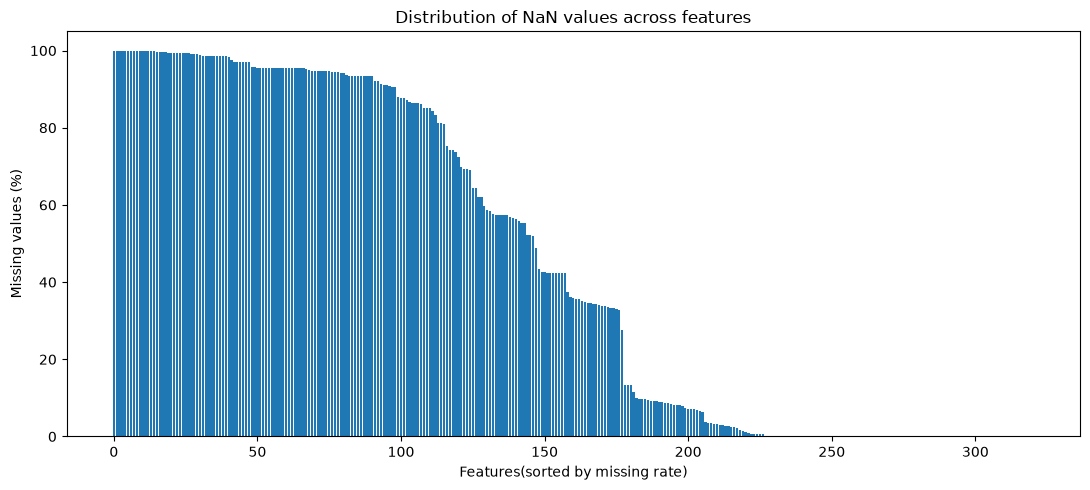

In [90]:
missing_rate = np.mean(np.isnan(x_train), axis=0)
order = np.argsort(missing_rate)[::-1]

print("Columns with at least one NaN:", np.count_nonzero(missing_rate))
print("Top 25 missing rates:")
for j in order[:25]:
    print(f"{feature_names[j]:<25} {missing_rate[j]:.2%}")

plt.figure(figsize=(11, 5))
plt.bar(np.arange(len(order)), missing_rate[order] * 100)
plt.xlabel("Features(sorted by missing rate)")
plt.ylabel("Missing values (%)")
plt.title("Distribution of NaN values across features")
plt.tight_layout()
plt.show()

From this plot, we can see that a large number of features have over $90\%$ of `NaN`  values. Notably, there are also features with around $30-80\%$ of `NaN`  values that could potentially be retained with imputation methods, such as mean or median imputation. Finally, around $100$ of the remaining features have very few or no `NaN`  values. However, this doesn't imply that a feature with a large number of missing values is irrelevant.


In [91]:
missing_candidates = [
    feature_names[j]
    for j in range(len(feature_names))
    if missing_rate[j] > 0.90
    and feature_names[j] not in features_to_drop
]

print("Features with more than 90% missing values:")
for feature in missing_candidates:
    j = list(feature_names).index(feature)
    print(f"{feature}: {missing_rate[j]:.2%}")

print("\nTotal candidates:", len(missing_candidates))

Features with more than 90% missing values:
COLGHOUS: 99.99%
LADULT: 99.99%
CCLGHOUS: 99.76%
NUMPHON2: 96.99%
INSULIN: 93.38%
BLDSUGAR: 93.38%
FEETCHK2: 93.38%
DOCTDIAB: 93.39%
CHKHEMO3: 93.39%
FEETCHK: 93.45%
EYEEXAM: 93.39%
DIABEYE: 93.39%
DIABEDU: 93.39%
CRGVREL1: 94.57%
CRGVLNG1: 94.57%
CRGVHRS1: 94.58%
CRGVPRB1: 94.59%
CRGVPERS: 94.59%
CRGVHOUS: 94.60%
CRGVMST2: 94.61%
VIDFCLT2: 99.28%
VIREDIF3: 99.28%
VIPRFVS2: 99.28%
VINOCRE2: 99.76%
VIEYEXM2: 99.43%
VIINSUR2: 99.28%
VICTRCT4: 99.28%
VIGLUMA2: 99.28%
VIMACDG2: 99.28%
CDHOUSE: 97.06%
CDASSIST: 97.06%
CDHELP: 99.06%
CDSOCIAL: 97.07%
CDDISCUS: 97.07%
WTCHSALT: 90.67%
LONGWTCH: 94.26%
DRADVISE: 90.68%
ASTHMAGE: 99.76%
ASATTACK: 99.85%
ASERVIST: 99.93%
ASDRVIST: 99.93%
ASRCHKUP: 99.85%
ASACTLIM: 99.85%
ASYMPTOM: 99.85%
ASNOSLEP: 99.90%
ASTHMED3: 99.85%
ASINHALR: 99.85%
HAREHAB1: 99.76%
STREHAB1: 99.84%
CVDASPRN: 95.72%
ASPUNSAF: 97.00%
RLIVPAIN: 98.72%
RDUCHART: 98.72%
RDUCSTRK: 98.72%
ARTTODAY: 95.56%
ARTHWGT: 95.56%
ARTHEXER: 95.56

A total of $99$ features have more than $90\%$ missing values, with some being almost entirely empty. These features are considered candidates for removal, as the limited amount of available data may reduce their usefulness for prediction.

## 5. Special Missing-Value Codes

In addition to `NaN`  values, some features use special numeric codes to represent missing responses, such as "Don't know" or "Refused". These codes are not automatically recognized as `NaN` and may be incorrectly interpreted as valid numerical values. Since the meaning of these codes depends on the feature, a selected set of variables was examined using the BRFSS documentation.


In [92]:
special_codes = {
    "GENHLTH": [7, 9],
    "BPHIGH4": [7, 9],
    "INCOME2": [77, 99],
    "DIABETE3": [7, 9],
    "SMOKE100": [7, 9],
    "TOLDHI2": [7, 9],
    "HAVARTH3": [7, 9],
    "DIFFWALK": [7, 9],
    "QLACTLM2": [7, 9],
    "PHYSHLTH": [77, 99],
    "MENTHLTH": [77, 99]
}

for feature, codes in special_codes.items():
    if feature not in feature_names:
        continue

    j = list(feature_names).index(feature)
    values = x_train[:, j]

    special_count = np.isin(values, codes).sum()
    missing_count = np.isnan(values).sum()

    original_rate = missing_count / len(values)
    corrected_rate = (missing_count + special_count) / len(values)

    print(f"\n{feature}")
    print(f"Special codes: {special_count}")
    print(f"Original missing rate: {original_rate:.2%}")
    print(f"Corrected missing rate: {corrected_rate:.2%}")


GENHLTH
Special codes: 886
Original missing rate: 0.00%
Corrected missing rate: 0.27%

BPHIGH4
Special codes: 917
Original missing rate: 0.00%
Corrected missing rate: 0.28%

INCOME2
Special codes: 56123
Original missing rate: 0.75%
Corrected missing rate: 17.86%

DIABETE3
Special codes: 474
Original missing rate: 0.00%
Corrected missing rate: 0.15%

SMOKE100
Special codes: 2409
Original missing rate: 3.21%
Corrected missing rate: 3.95%

TOLDHI2
Special codes: 2523
Original missing rate: 13.35%
Corrected missing rate: 14.12%

HAVARTH3
Special codes: 1882
Original missing rate: 0.00%
Corrected missing rate: 0.57%

DIFFWALK
Special codes: 1630
Original missing rate: 2.79%
Corrected missing rate: 3.28%

QLACTLM2
Special codes: 2215
Original missing rate: 2.11%
Corrected missing rate: 2.79%

PHYSHLTH
Special codes: 7107
Original missing rate: 0.00%
Corrected missing rate: 2.17%

MENTHLTH
Special codes: 5359
Original missing rate: 0.00%
Corrected missing rate: 1.63%


The results show that special missing value codes can significantly increase the percentage of missing data. This is particularly noticeable for `INCOME2`, where the missing rate increases from $0.75\%$ to $17.86%\$ after including these codes. For other features, the difference is smaller but still worth considering. This shows that relying only on `NaN` values can underestimate the actual amount of missing data. Therefore, special codes should be handled according to the BRFSS codebook during preprocessing.

## 6. Constant and Near-Constant Features

Some features may contain the same value for all rows or be dominated by a single value. These are known as constant and near-constant features. Constant features provide no useful information for distinguishing between classes, while near-constant features may have limited predictive value. Analyzing these features helps identify those with very little variation, which may provide limited information for predicting the target variable.

In [93]:
constant_features = []
near_constant_features = []

for j, feature in enumerate(feature_names):
    values = x_train[:, j]
    valid = values[~np.isnan(values)]

    if len(valid) == 0:
        continue

    unique, counts = np.unique(valid, return_counts=True)

    if len(unique) == 1:
        constant_features.append(feature)

    elif counts.max() / len(valid) > 0.99:
        near_constant_features.append(
            (feature, counts.max() / len(valid))
        )

near_constant_features.sort(key=lambda x: x[1], reverse=True)

print("Constant features:", len(constant_features))
print(constant_features)

print("\nNear-constant features:", len(near_constant_features))

for feature, proportion in near_constant_features:
    print(f"{feature:<20} {proportion:.2%}")

Constant features: 6
[np.str_('CTELENUM'), np.str_('COLGHOUS'), np.str_('STATERES'), np.str_('CTELNUM1'), np.str_('CELLFON2'), np.str_('CCLGHOUS')]

Near-constant features: 4
_VEG23               99.99%
PVTRESD1             99.98%
_FRT16               99.98%
PVTRESD2             99.42%


The analysis identified $6$ constant features and $4$ near-constant features. For the near-constant features, more than $99\%$ of the non-missing values belong to the same category. While constant features contain no variation among their non-missing values, near-constant features may still provide useful information for prediction.

In [94]:
features_to_check = constant_features + [
    feature for feature, _ in near_constant_features
]

print(f"{'Feature':<15} {'Missing %':>10} {'Unique':>8}")

for feature in features_to_check:
    j = list(feature_names).index(feature)
    values = x_train[:, j]

    missing = np.isnan(values).mean() * 100
    unique = len(np.unique(values[~np.isnan(values)]))

    print(f"{feature:<15} {missing:>9.2f}% {unique:>8}")

Feature          Missing %   Unique
CTELENUM            42.49%        1
COLGHOUS            99.99%        1
STATERES            42.49%        1
CTELNUM1            57.51%        1
CELLFON2            57.51%        1
CCLGHOUS            99.76%        1
_VEG23               0.00%        2
PVTRESD1            42.49%        2
_FRT16               0.00%        2
PVTRESD2            57.51%        2


The results also show that some of these features have a high percentage of `NaN` values. For example, `COLGHOUS` is almost entirely missing, while `_VEG23` has no `NaN` values despite being near-constant. This shows that features with little variation do not necessarily have high missing rates. Additionally, missing value patterns may still contain useful information, so these features should not automatically be removed.

## 7. Feature distributions

In this section, the distributions of six selected features are examined to better understand how their values are represented in the dataset. The features were selected based on previous research linking age, high blood pressure, high cholesterol, diabetes, smoking, and general health status to cardiovascular disease. Since these features are categorical, bar charts are used to visualize their distributions. Missing values and known special missing value codes are excluded from the analysis.

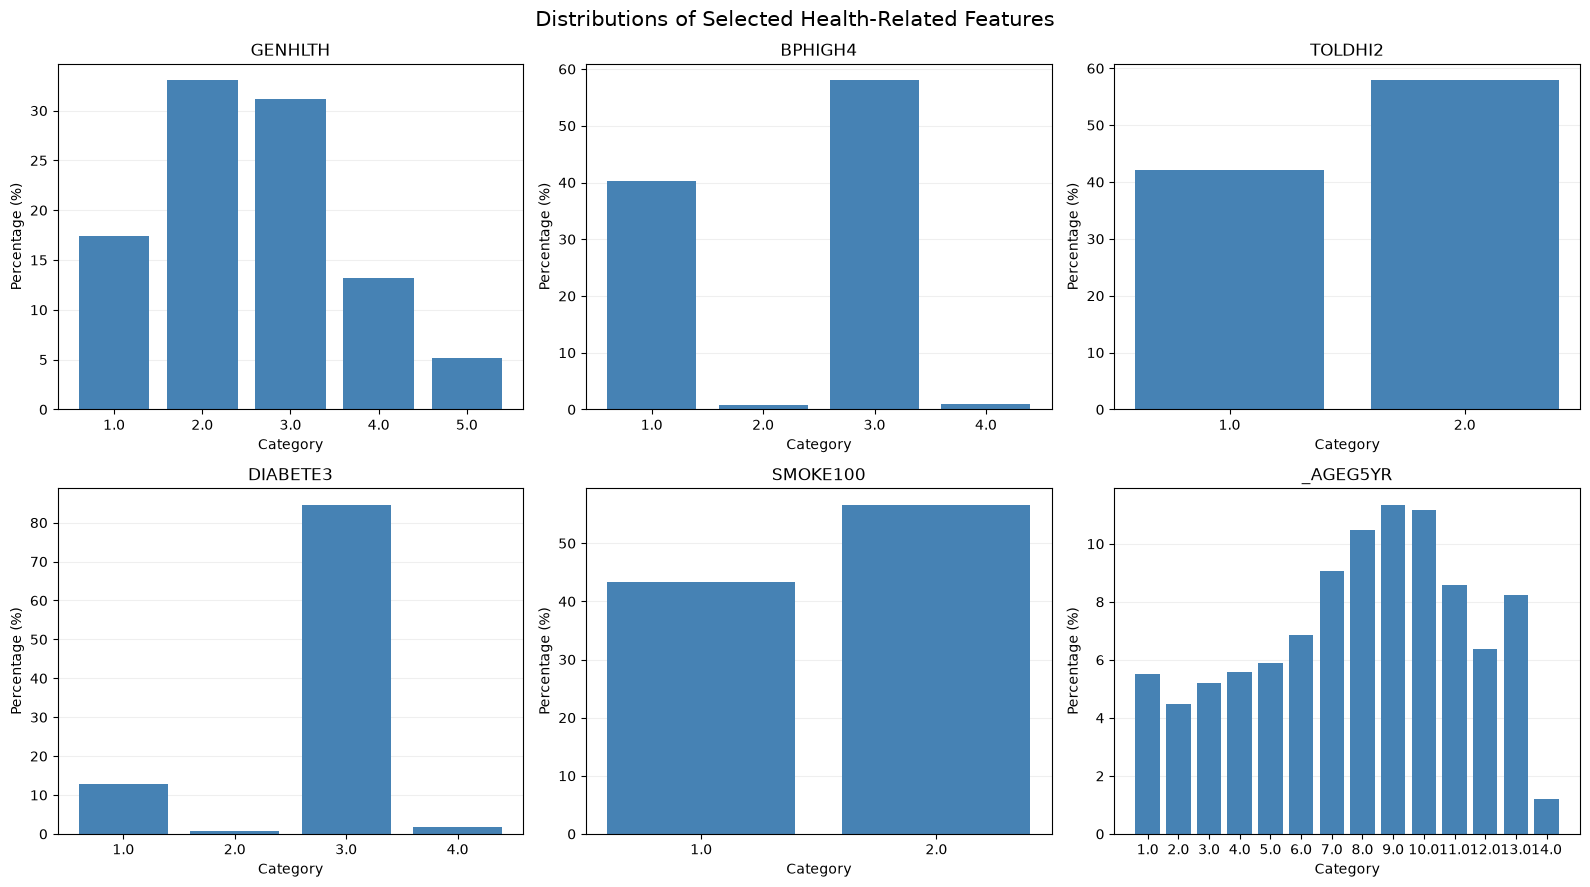

In [95]:
selected_features = [
    "GENHLTH", "BPHIGH4", "TOLDHI2",
    "DIABETE3", "SMOKE100", "_AGEG5YR"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, feature in zip(axes, selected_features):
    if feature not in feature_names:
        ax.set_visible(False)
        continue

    j = list(feature_names).index(feature)
    values = x_train[:, j]

    #Exclude NaN and known special missing codes
    valid = ~np.isnan(values)
    if feature in special_codes:
        valid &= ~np.isin(values, special_codes[feature])
    values = values[valid]

    categories, counts = np.unique(values, return_counts=True)
    percentages = counts / counts.sum() * 100

    ax.bar(categories.astype(str), percentages, color="steelblue")
    ax.set_title(feature)
    ax.set_ylabel("Percentage (%)")
    ax.set_xlabel("Category")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.suptitle("Distributions of Selected Health-Related Features", fontsize=15)
plt.tight_layout()
plt.show()

The distributions show that most respondents reported good or very good general health, while the majority didn't report diabetes. Some features, such as `BPHIGH4` and `SMOKE100`, are more evenly distributed, while `_AGEG5YR` shows a higher proportion of middle-aged and older respondents. These plots provide an overview of the selected features, while their relationship with `_MICHD` will be examined in the following analysis.

## 8. Feature–target relationships

In this section, the relationship between selected features and the target variable `_MICHD` is examined. For each category, the percentage of respondents with a positive target value is calculated and visualized. This helps identify which features and categories are associated with a higher proportion of positive cases. A positive `_MICHD` value indicates that a respondent has reported a previous diagnosis of coronary heart disease or myocardial infarction.

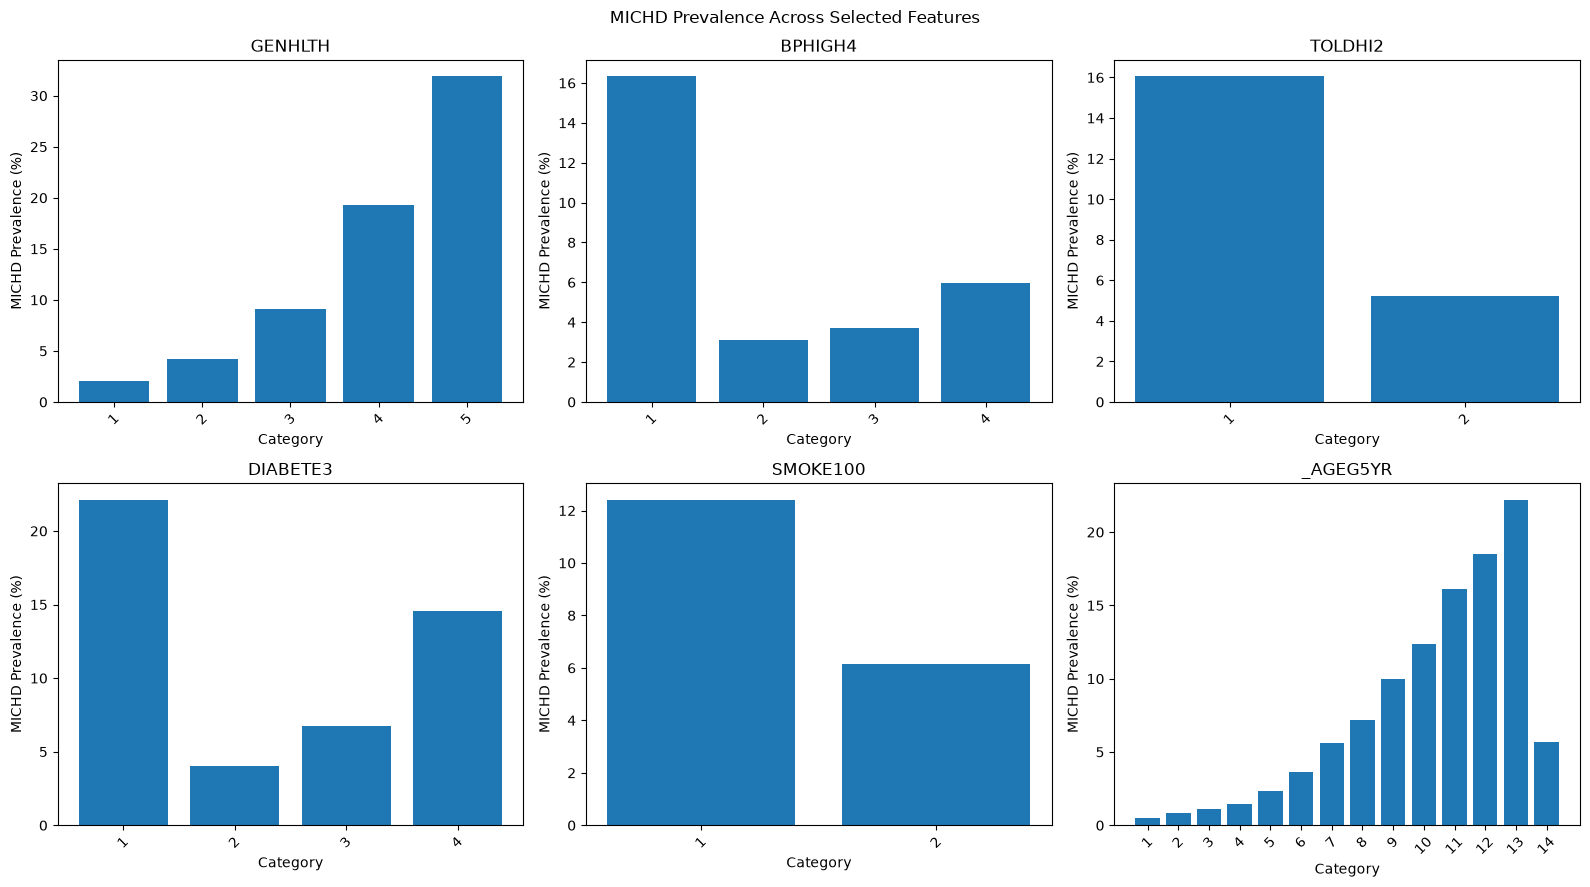

In [96]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, name in zip(axes.flatten(), selected_features):
    j = list(feature_names).index(name)
    values = x_train[:, j]

    valid = ~np.isnan(values)

    if name in special_codes:
        valid &= ~np.isin(values, special_codes[name])

    categories = np.unique(values[valid])

    positive_rates = []

    for category in categories:
        mask = valid & (values == category)
        rate = np.mean(y_train[mask] == 1) * 100
        positive_rates.append(rate)

    ax.bar([f"{v:g}" for v in categories], positive_rates)
    ax.set_title(name)
    ax.set_xlabel("Category")
    ax.set_ylabel("MICHD Prevalence (%)")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("MICHD Prevalence Across Selected Features")
plt.tight_layout()
plt.show()

The results show that positive `_MICHD` rates generally increase with age and poorer self-reported health. Higher rates are also observed among respondents reporting diabetes, high blood pressure, high cholesterol, or a history of smoking. These patterns are consistent with known cardiovascular risk factors. However, the results represent associations within the dataset and do not imply causation. The percentages are calculated within each category and are not adjusted for other factors, such as age.

## 9.1. Pearson correlation

In this section, Pearson correlation is used to examine the linear relationships between selected numerical features. A correlation matrix is used to visualize the strength and direction of these relationships. This analysis helps identify features that may contain overlapping information, which could be relevant for further preprocessing and model development.

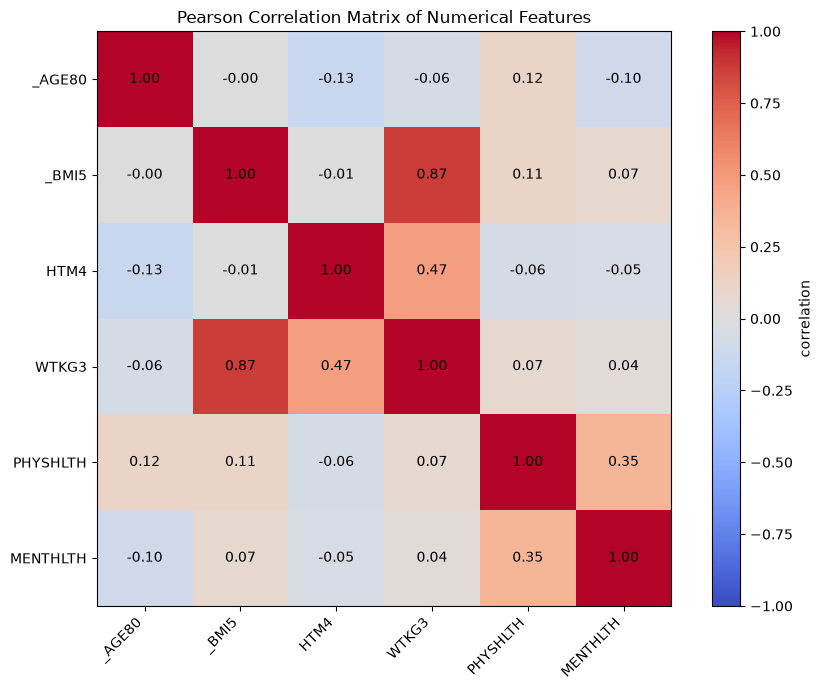

In [97]:
numerical_features = [
    "_AGE80", "_BMI5", "HTM4", "WTKG3",
    "PHYSHLTH", "MENTHLTH"
]

data = []

for name in numerical_features:
    j = list(feature_names).index(name)
    values = x_train[:, j].copy()

    if name in ["PHYSHLTH", "MENTHLTH"]:
        values[values == 88] = 0
        values[np.isin(values, [77, 99])] = np.nan

    data.append(values)

data = np.column_stack(data)

n = len(numerical_features)
corr_matrix = np.full((n, n), np.nan)

for i in range(n):
    for j in range(n):
        valid = np.isfinite(data[:, i]) & np.isfinite(data[:, j])

        x = data[valid, i]
        y = data[valid, j]

        if len(x) > 1 and np.std(x) > 0 and np.std(y) > 0:
            corr_matrix[i, j] = np.corrcoef(x, y)[0, 1]

fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(numerical_features, rotation=45, ha="right")
ax.set_yticklabels(numerical_features)

for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{corr_matrix[i, j]:.2f}",
                ha="center", va="center", fontsize=10)

plt.colorbar(im, ax=ax, label="correlation")
ax.set_title("Pearson Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()

The correlation matrix shows that BMI and weight have the strongest positive correlation, which is expected since weight is used to calculate BMI. Positive correlations are also found between height and weight, as well as between the number of days of poor physical and mental health. Most other features show relatively weak linear relationships. Although the strong correlation between BMI and weight suggests that they may contain overlapping information, this alone is not enough to justify removing either feature from the dataset.

## 9.2. Categorical Feature Correlation

Cramér's V is used to examine relationships between categorical features, since their numerical codes do not necessarily represent meaningful numerical values. The association matrix helps identify features that are strongly related and may contain overlapping information. In particular, some BRFSS features are derived from other survey responses, so strong associations between them are expected.

In [98]:
#Identify potential categorical features
unique_counts = np.array([
    len(np.unique(x_train[~np.isnan(x_train[:, j]), j]))
    for j in range(x_train.shape[1])
])

categorical_features = [
    feature_names[j]
    for j in range(len(feature_names))
    if 2 <= unique_counts[j] <= 15
    and missing_rate[j] < 0.5
    and feature_names[j] not in features_to_drop
]

print(f"Potential categorical features: {len(categorical_features)}")
print(categorical_features)

Potential categorical features: 108
[np.str_('PVTRESD1'), np.str_('CELLFON3'), np.str_('NUMMEN'), np.str_('NUMWOMEN'), np.str_('GENHLTH'), np.str_('HLTHPLN1'), np.str_('PERSDOC2'), np.str_('MEDCOST'), np.str_('CHECKUP1'), np.str_('BPHIGH4'), np.str_('BLOODCHO'), np.str_('CHOLCHK'), np.str_('TOLDHI2'), np.str_('CVDSTRK3'), np.str_('ASTHMA3'), np.str_('CHCSCNCR'), np.str_('CHCOCNCR'), np.str_('CHCCOPD1'), np.str_('HAVARTH3'), np.str_('ADDEPEV2'), np.str_('CHCKIDNY'), np.str_('DIABETE3'), np.str_('SEX'), np.str_('MARITAL'), np.str_('EDUCA'), np.str_('RENTHOM1'), np.str_('NUMHHOL2'), np.str_('CPDEMO1'), np.str_('VETERAN3'), np.str_('EMPLOY1'), np.str_('INCOME2'), np.str_('INTERNET'), np.str_('QLACTLM2'), np.str_('USEEQUIP'), np.str_('BLIND'), np.str_('DECIDE'), np.str_('DIFFWALK'), np.str_('DIFFDRES'), np.str_('DIFFALON'), np.str_('SMOKE100'), np.str_('USENOW3'), np.str_('EXERANY2'), np.str_('SEATBELT'), np.str_('FLUSHOT6'), np.str_('PNEUVAC3'), np.str_('HIVTST6'), np.str_('QSTVER'), np.st

In [99]:

def cramers_v_between(feature1, feature2):
    j1 = np.where(feature_names == feature1)[0][0]
    j2 = np.where(feature_names == feature2)[0][0]

    x = x_train[:, j1]
    y = x_train[:, j2]

    valid = np.isfinite(x) & np.isfinite(y)

    cats_x, ix = np.unique(x[valid], return_inverse=True)
    cats_y, iy = np.unique(y[valid], return_inverse=True)

    if len(cats_x) < 2 or len(cats_y) < 2:
        return np.nan

    observed = np.zeros((len(cats_x), len(cats_y)))
    np.add.at(observed, (ix, iy), 1)

    expected = (
        observed.sum(axis=1, keepdims=True)
        * observed.sum(axis=0, keepdims=True)
        / observed.sum()
    )

    chi2 = np.sum((observed - expected)**2 / expected)

    return np.sqrt(
        chi2 / (
            observed.sum()
            * min(len(cats_x) - 1, len(cats_y) - 1)
        )
    )


In [100]:
n = len(categorical_features)
cramers_matrix = np.eye(n)

for i in range(n):
    for j in range(i + 1, n):
        v = cramers_v_between(
            categorical_features[i],
            categorical_features[j]
        )

        cramers_matrix[i, j] = v
        cramers_matrix[j, i] = v

print("Matrix shape:", cramers_matrix.shape)

Matrix shape: (108, 108)


In [101]:
# Ignore diagonal values
strength = cramers_matrix.copy()
np.fill_diagonal(strength, np.nan)

# Strongest association of each feature with another feature
max_association = np.array([
    np.nanmax(row) if np.any(np.isfinite(row)) else -1
    for row in strength
])

top_indices = np.argsort(max_association)[-10:][::-1]

top_features = [categorical_features[i] for i in top_indices]

top_matrix = cramers_matrix[np.ix_(top_indices, top_indices)]

print("Selected features:", top_features)

Selected features: [np.str_('_AIDTST3'), np.str_('_RFSEAT3'), np.str_('_RFSEAT2'), np.str_('_LMTSCL1'), np.str_('_LMTWRK1'), np.str_('_LMTACT1'), np.str_('_PASTAE1'), np.str_('_PAREC1'), np.str_('_PA30021'), np.str_('_PA300R2')]


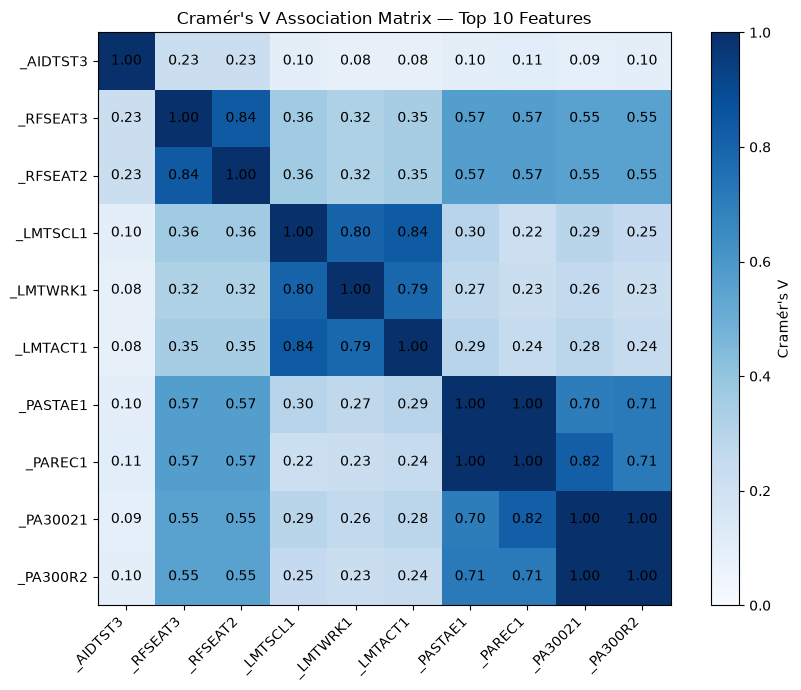

In [102]:
plt.figure(figsize=(9, 7))

plt.imshow(top_matrix, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Cramér's V")

plt.xticks(range(10), top_features, rotation=45, ha="right")
plt.yticks(range(10), top_features)

for i in range(10):
    for j in range(10):
        plt.text(
            j, i,
            f"{top_matrix[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Cramér's V Association Matrix — Top 10 Features")
plt.tight_layout()
plt.show()

The Cramér's V matrix shows that several categorical features are strongly associated with each other. The strongest relationships are found between features related to physical activity, while features describing physical limitations also show strong associations. This suggests that some features may contain similar information, particularly those measuring related aspects of health and lifestyle. On the other hand, `_AIDTST3` shows weaker associations with the other selected features. These findings help identify possible redundancy in the dataset, although further analysis would be needed before deciding whether to remove any features.

## 10. Principal Component Analysis (PCA)

PCA is used to explore whether the dataset can be represented using fewer dimensions while preserving most of its variance. Features with less than $50%$ missing values are selected, excluding the previously identified features to drop. Missing values are replaced with column medians, and the features are standardized before applying PCA. The explained variance and the first two principal components are then visualized to better understand the structure of the data.

In [103]:
cols = [
    j for j in range(len(feature_names))
    if missing_rate[j] < 0.5
    and feature_names[j] not in features_to_drop
]

X = x_train[:, cols].copy()

#Replace missing values with column medians
medians = np.nanmedian(X, axis=0)
X = np.where(np.isnan(X), medians, X)

#Standardize features
X = (X - X.mean(axis=0)) / np.where(X.std(axis=0) > 0, X.std(axis=0), 1)

#PCA
eigvals, eigvecs = np.linalg.eigh(X.T @ X / len(X))
eigvals = eigvals[::-1]
eigvecs = eigvecs[:, ::-1]

explained = np.cumsum(np.maximum(eigvals, 0)) / np.maximum(eigvals, 0).sum()

print("Components for 90% variance:", np.searchsorted(explained, 0.90) + 1)
print("Components for 95% variance:", np.searchsorted(explained, 0.95) + 1)


Components for 90% variance: 78
Components for 95% variance: 94


The PCA results show that $78$ principal components are needed to preserve $90\%$ of the total variance, while $84$ components are needed to preserve $95\%$. This suggests that the variance is spread across many components, meaning that reducing the dataset to only a few dimensions would lead to a considerable loss of information.

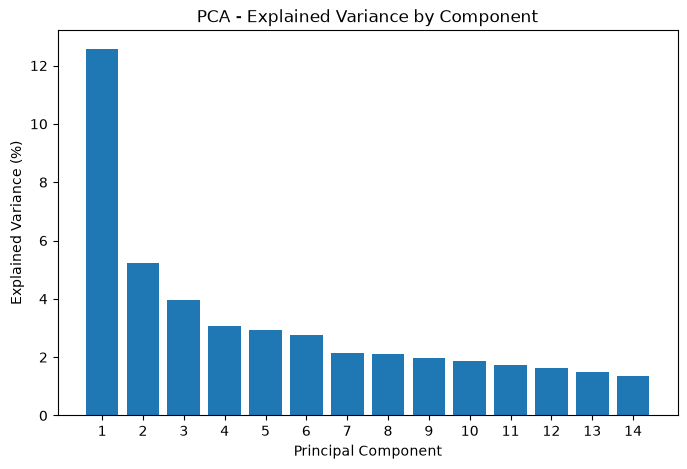

In [104]:
#Explained variance of the first 14 principal components
variance_ratio = eigvals / eigvals.sum()

plt.figure(figsize=(8, 5))
plt.bar(
    np.arange(1, 15),
    variance_ratio[:14] * 100
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance (%)")
plt.title("PCA - Explained Variance by Component")
plt.xticks(np.arange(1, 15))
plt.show()


The first principal component explains the largest share of the total variance, while the following components contribute progressively less. The explained variance decreases relatively quickly at first and then becomes more evenly distributed across the remaining components. This suggests that the variance is spread across many components rather than being concentrated in just a few.

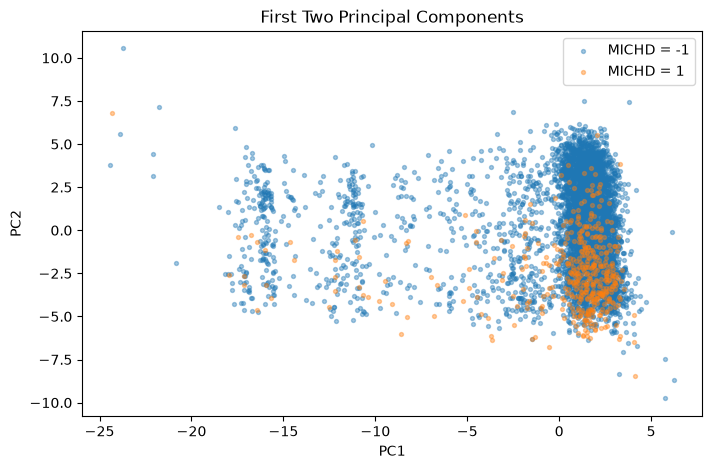

In [105]:
#Scatter plot of first two principal components
rng = np.random.default_rng(42)
idx = rng.choice(len(X), size=5000, replace=False)

X_2d = X[idx] @ eigvecs[:, :2]

plt.figure(figsize=(8, 5))

for label in [-1, 1]:
    mask = y_train[idx] == label
    plt.scatter(X_2d[mask, 0], X_2d[mask, 1],
                s=8, alpha=0.4, label=f"MICHD = {label}")

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("First Two Principal Components")
plt.legend()
plt.show()

The scatter plot shows considerable overlap between the two target classes, indicating that the first two principal components do not clearly separate them. However, additional components may provide more useful information for distinguishing between the classes.

## Initial Preprocessing Strategies

Based on the exploratory data analysis, three initial preprocessing strategies are proposed for comparison.

**1. Basic preprocessing:** Remove administrative, highly missing, and constant features. Handle special missing-value codes, impute missing values, and standardize numerical features.

**2. Correlation-based preprocessing:** Extend the basic approach by identifying and removing selected redundant features based on Pearson correlation and Cramér's V. Apply appropriate encoding to categorical features.

**3. PCA-based preprocessing:** Apply the necessary cleaning, encoding, and scaling steps, followed by PCA to reduce dimensionality while preserving a selected percentage of the total variance.

These strategies will be evaluated using the same models and performance metrics to determine whether additional feature selection or dimensionality reduction improves predictive performance.